#### Hyperparameters

In [9]:
from adaptive.ADPIMH import BAIM, IndMH, pCN, adp_only
from adaptive.ADPestimators import First_Est, Odd_ratio, Second_Est
from adaptive.Distributions import Stochastic_Volatility, Bayesian_Logistic_Regression
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

is_sim = True
if is_sim:
    d = 15                  # dimensions
else:
    d = 53

epoch = 10                    # Number of estimator replications
Sample_N = 5000                        # Number of Samples collected from MCMC
df = 1000

lr_burnin = 0.001                     # learning rate
Itr_burnin = 200000                  # Number of iterations of MCMC
batch_size_burnin = 50

lr = 0.005
Itr = 12000
batch_size = 100

m = -0.86
phi = 0.98
s = 0.15

distribution1 = "multivariate_normal"
distribution2 = "stochastic_volatility"
distribution3 = "student_t"
distribution4 = "bayesian_logistic_regression"
dataset = "heart" #'caravan', 'pima',  'ripley', 'australian','german', 'heart'

proposal = distribution1  # Target and Proposal distribution
target = distribution4
iscmc = False
                
def moving_average(a, n) :
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n :] - ret[: -n]
    return ret[n - 1 :] / n

#### Set $\mu$ and $L$

In [16]:
from sklearn.linear_model import LogisticRegression

if target == "stochastic_volatility":
    est = Stochastic_Volatility(d, m, phi,s) #1. m 2. phi 3. s
    est.load_data(is_sim)
    mu1 = None
    L1 = None
    mu2 = np.zeros(d)
    L2 = np.eye(d)
elif target == "bayesian_logistic_regression":
    est = Bayesian_Logistic_Regression()
    est.load_data(dataset)
    d = np.shape(est.inputs)[1] + 1
    Fit = LogisticRegression()
    para = Fit.fit(est.inputs, est.outputs)

    true_mean = np.append(para.coef_,para.intercept_)
    
    col_ones = np.ones((est.inputs.shape[0], 1), dtype=jnp.float64)
    est.inputs = jnp.concatenate((est.inputs, col_ones), axis=1)

    print(est.inputs.shape)

    # xs = est.inputs @ true_mean.T
    # xxs = np.exp(xs) / (1 + np.exp(xs)) ** 2
    # xxs1 = 1 / (1 + np.exp(xs)) **2
    # W = np.diag(xxs)
    # Wh = np.diag(xxs1)
    # c = np.linalg.inv(est.inputs.T @ W @ est.inputs)
    # c1 = est.inputs.T @ Wh @ est.inputs
    # cov = c @ c1 @ c
    # true_L = np.linalg.cholesky(cov)

    mu1 = None
    L1 = None
    print(true_mean)
    L2 = np.eye(d)
    mu2 = true_mean
    # mu2 = np.array([2.15,12.39,-6.28])
    # L2 = np.array([[0.262,0.336,-0.177],[0.336,2.434,-1.25],[-0.177,-1.25,0.68]])
else:
    est = None
    mu1 = np.zeros(d)    # mu1 = [0,0,...,0], L1 = diag(1) is the target distribution
    L1 = np.eye(d)      # mu2 = [1,1,...,1], L2 = L1*1.1 is the proposal distribution
    mu2 = np.ones(d)
    L2 = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            if i >= j:
                L2[i, j] = 1
    L2 = np.eye(d)

(270, 14)
[-0.12567388  0.66770824  0.63576481  0.40669258  0.33831476 -0.25378689
  0.29029078 -0.45776198  0.3789035   0.39149691  0.25266945  1.01789861
  0.64871876 -0.25386432]


/home/cliusir/anaconda3/envs/statr/lib/python3.10/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


300/300 batches adapted !

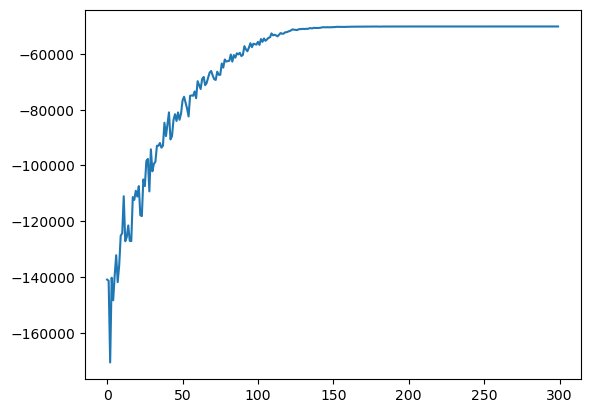

600/600 batches adapted !

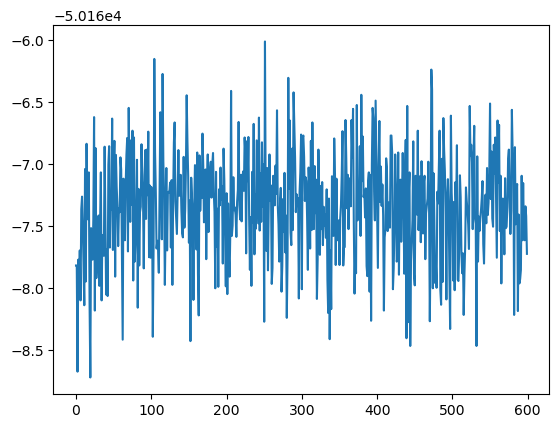

200/200 batches adapted !

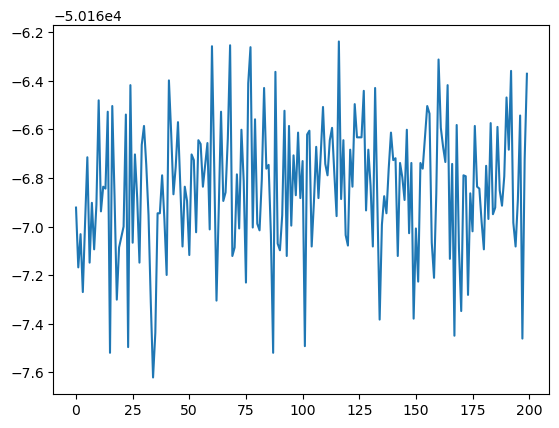

In [17]:
lr_fast = 0.01                     # learning rate
Itr_fast = 3000                  # Number of iterations of MCMC
batch_size_fast = 10
Myadpfast = adp_only(target, proposal,Itr_fast, batch_size_fast ,d, lr_fast,est,df)
Myadpfast.set_distribution_parameters(mu1,L1,mu2,L2)
resul1 = Myadpfast.adp(True)
plt.plot(resul1)
plt.show()
mu2 = Myadpfast.p_mean
L2 = Myadpfast.p_L

lr_burnin = 0.001                     # learning rate
Itr_burnin = 30000                  # Number of iterations of MCMC
batch_size_burnin = 50
Myadp = adp_only(target, proposal,Itr_burnin, batch_size_burnin,d,lr_burnin,est,df)
Myadp.set_distribution_parameters(mu1,L1,mu2,L2)
resul1 = Myadp.adp(True)
plt.plot(resul1)
plt.show()
mu2 = Myadp.p_mean
L2 = Myadp.p_L

lr_burnin = 0.0001                     # learning rate
Itr_burnin = 20000                  # Number of iterations of MCMC
batch_size_burnin = 100
Myadp = adp_only(target, proposal,Itr_burnin, batch_size_burnin,d,lr_burnin,est,df)
Myadp.set_distribution_parameters(mu1,L1,mu2,L2)
resul1 = Myadp.adp(True)
plt.plot(resul1)
plt.show()
mu2 = Myadp.p_mean
L2 = Myadp.p_L

In [5]:
print(mu2)
np.set_printoptions(suppress=True)
print((L2 @ L2.T))
print(np.abs((L2 @ L2.T) - np.eye(d))/(d*d))

[ 1.20694    5.078776  -2.4683952]
[[ 0.10080193  0.01302516 -0.00508575]
 [ 0.01302516  0.32436085 -0.1613661 ]
 [-0.00508575 -0.1613661   0.10312524]]
[[0.09991089 0.00144724 0.00056508]
 [0.00144724 0.07507101 0.01792957]
 [0.00056508 0.01792957 0.09965275]]


In [ ]:
beta = 0
Mypcn = pCN(target, distribution1, Itr, d, lr, est, df, beta)
Mypcn.set_distribution_parameters(mu1,L1,mu2,L2)
resul2 = Mypcn.pCN_MCMC()
# 0: t_sample, 1: p_sample, 2:acc_rate 3:means 4:is_accepted 5: log_target

print(resul2[4].mean())

k = moving_average(resul2[4],100)
t = np.argmax(k)

plt.plot(k)
plt.show()

In [ ]:
import tensorflow_probability as tfp
import tensorflow as tf
epoch = 50
Itr = 2000
results = []
for i in range(epoch):
    print(str(i + 1)+'/' + str(epoch)+' epoch')
    beta = 0
    Mypcn = pCN(target, proposal, Itr, d, lr, est, df, beta, i+10)
    Mypcn.set_distribution_parameters(mu1,L1,mu2,L2)
    resul2 = Mypcn.pCN_MCMC()
    results.append(resul2)


In [ ]:
Sample_N = 1000
Ans = np.zeros((epoch,d))
Ans1 = np.zeros((epoch,d))
Ans2 = np.zeros((epoch,d))
for i in range(epoch):
    A = results[i][0]
    B = results[i][1]
    C = results[i][2]
    D = results[i][3]

# Ess = tfp.mcmc.effective_sample_size(tf.convert_to_tensor(A))
# print(Ess)
    for j in range(d):
        Esti = First_Est(Sample_N, batch_size, j)
        Esti.sample_loader(A,B,C,D)
        Ans[i,j] = Esti.IM()[0]
        Ans1[i,j] = Esti.IMCV()[0]
        Ans2[i,j] = Esti.IMCV2()[0]
        # Main = Esti.F(Esti.X)
        # Poisson_cv = Esti.Acpt * (Esti.F(Esti.Y) - Esti.F(Esti.X))
        # Static_cv = Esti.F(Esti.Y) - Esti.analytics(Esti.pMeans)
        # plt.scatter(Poisson_cv, Static_cv)
        # coef_2 = np.sum((Static_cv - np.mean(Static_cv))*(Poisson_cv - np.mean(Poisson_cv)))/np.sum((Static_cv - np.mean(Static_cv))**2)
        # print(coef_2)
        # print(np.var(Poisson_cv - Static_cv))
        # print(np.var(Poisson_cv - coef_2 * Static_cv))

print(Ans.mean(axis = 0)), print(Ans1.mean(axis = 0)), print(Ans2.mean(axis = 0))
print(Ans.var(axis = 0) / Ans1.var(axis = 0))
print(Ans.var(axis = 0) / Ans2.var(axis = 0))
print(min(Ans.var(axis = 0) / Ans1.var(axis = 0)), max(Ans.var(axis = 0) / Ans1.var(axis = 0)))
print(min(Ans.var(axis = 0) / Ans2.var(axis = 0)), max(Ans.var(axis = 0) / Ans2.var(axis = 0)))
# fig, axs = plt.subplots(1,d)
# for i in range(d):
#     axs[i].boxplot((Ans[:,i],Ans1[:,i]), labels=('IMCV','IM'), positions=(0.2,0.8))
# plt.show()



In [ ]:
from matplotlib import cm
Meanscv = Ans2.mean(axis = 0)
G = np.meshgrid(np.linspace(-1.5, 1, 100), np.linspace(-0.5, 1.2, 100))
P = 1/(1+np.exp(-Meanscv[2] - Meanscv[0]*G[0]- Meanscv[1]*G[1]))

plt.scatter(est.inputs[est.outputs == 1,0],est.inputs[est.outputs == 1,1],c='r',s=10)
plt.scatter(est.inputs[est.outputs == 0,0],est.inputs[est.outputs == 0,1],c='b',s=10)
plt.contourf(G[0], G[1], P, 100, cmap=cm.jet, alpha=0.3)

In [22]:
MyIMHpre2 = BAIM(target, proposal,100000,500, d, 0.0001, est, df,11)
MyIMHpre2.set_distribution_parameters(mu1, L1, mu2, L2)
resul2 = MyIMHpre2.adpIMH()
mu2 = MyIMHpre2.p_mean
L2 = MyIMHpre2.p_L
print("Initialization completed!")

200/200 batches adapted !Initialization completed!


In [ ]:

# 0:t_sample \ 1:p_sample \ 2:accp_rate \ 3:paras \ 4:loss \ 5: logtar \ 6: is_acc
k = moving_average(resul2[6],500)
t = np.argmax(k)

plt.plot(k)
plt.ylabel('Acceptance Probability')
plt.show()
plt.plot(resul2[4])
plt.title('Value of loss function for Stochastic Volatility')
plt.ticklabel_format(axis = 'y', style = 'sci', scilimits= (-1,2))
plt.xlabel('number of batches')
plt.ylabel('value of loss function')
plt.show()
plt.plot(resul2[5])
plt.show()
print(MyIMHpre2.p_mean, MyIMHpre2.p_L)

pd.DataFrame(k).to_csv('acceptanceg.csv')


In [20]:
results = []
epoch = 50

lr = 0
batch_size = 50
Sample_N = batch_size * 20
Itr = Sample_N+1000

for i in range(epoch):
    print('\n',i + 1, ' th epoch')
    MyIMHpre2 = BAIM(target, proposal, Itr, batch_size, d, lr, est, df, i + 10)
    MyIMHpre2.set_distribution_parameters(mu1, L1, mu2, L2)
    resul2 = MyIMHpre2.adpIMH()
    results.append(resul2)




 1  th epoch
40/40 batches adapted !
 2  th epoch
40/40 batches adapted !
 3  th epoch
40/40 batches adapted !
 4  th epoch
40/40 batches adapted !
 5  th epoch
40/40 batches adapted !
 6  th epoch
40/40 batches adapted !
 7  th epoch
40/40 batches adapted !
 8  th epoch
40/40 batches adapted !
 9  th epoch
40/40 batches adapted !
 10  th epoch
40/40 batches adapted !
 11  th epoch
40/40 batches adapted !
 12  th epoch
40/40 batches adapted !
 13  th epoch
40/40 batches adapted !
 14  th epoch
40/40 batches adapted !
 15  th epoch
40/40 batches adapted !
 16  th epoch
40/40 batches adapted !
 17  th epoch
40/40 batches adapted !
 18  th epoch
40/40 batches adapted !
 19  th epoch
40/40 batches adapted !
 20  th epoch
40/40 batches adapted !
 21  th epoch
40/40 batches adapted !
 22  th epoch
40/40 batches adapted !
 23  th epoch
40/40 batches adapted !
 24  th epoch
40/40 batches adapted !
 25  th epoch
40/40 batches adapted !
 26  th epoch
40/40 batches adapted !
 27  th epoch
40/40 

In [21]:
Ans = np.zeros((epoch,d + 1))
Ans1 = np.zeros((epoch,d + 1))
Ans2= np.zeros((epoch,d + 1))
Bns = np.zeros((epoch,d))
Bns1 = np.zeros((epoch,d))
Bns2= np.zeros((epoch,d))
accm = np.zeros((epoch,1))
for i in range(epoch):
    A = results[i][0]
    B = results[i][1]
    C = results[i][2]
    D = results[i][3]
    E = results[i][6]
    accm[i] = np.mean(E)
# Ess = tfp.mcmc.effective_sample_size(tf.convert_to_tensor(A))
# print(Ess)
    for j in range(d):
        Esti = First_Est(Sample_N, batch_size, j)
        Esti.sample_loader(A,B,C,D[0])
        Ans2[i,j] = Esti.BatchIMCV2()[0]
        Ans1[i,j] = Esti.BatchIMCV()[0]
        Ans[i,j] = Esti.IM()[0]
        Esti3 = Second_Est(Sample_N, batch_size, j)
        Esti3.sample_loader(A,B,C,D)
        Bns2[i,j] = Esti3.BatchIMCV2()[0]
        Bns1[i,j] = Esti3.BatchIMCV()[0]
        Bns[i,j] = Esti3.IM()[0]

    Esti2 = Odd_ratio(Sample_N, batch_size)
    Esti2.sample_loader(A,B,C,D)
    Esti2.pre_proc(est.inputs)
    Ans2[i,d] = Esti2.BatchIMCV2()[0]
    Ans1[i,d] = Esti2.BatchIMCV()[0]
    Ans[i,d] = Esti2.IM()[0]
accm_mean = accm.mean()
VRF1 = Ans.var(axis = 0) / Ans1.var(axis = 0)
VRF2 = Ans.var(axis = 0) / Ans2.var(axis = 0)
BVRF1 = Bns.var(axis = 0) / Bns1.var(axis = 0)
BVRF2 = Bns.var(axis = 0) / Bns2.var(axis = 0)
print(accm.mean())
print(VRF1)
print(VRF2)
print(BVRF1)
print(BVRF2)
print(min(VRF1[0:d-1]), max(VRF1[0:d-1]))
print(min(VRF2[0:d-1]), max(VRF2[0:d-1]))
print(min(BVRF1), max(BVRF1))
print(min(BVRF2), max(BVRF2))
print(VRF2[-1])

0.8724199999999999
[15.86206435 12.40288838 11.85712808 13.24544671  6.5004195  12.08043475
 14.67532913  7.15058639  7.87409456  9.76756052 18.51677589  8.37505937
  6.86813932 12.48925623 12.51627192]
[13.21886163 11.55195955  9.77525787 12.90869235  7.91367943 12.7961597
 13.94765375  6.65243476  7.91184594 10.11259827 14.42696348  8.37687782
  6.09268358 11.17264605 11.20050581]
[ 6.5800785   6.3372258  16.31752958  7.36100925 14.6585869   8.36646516
 10.77657144 12.14301965  3.66111552  7.39366835  9.91335217  9.19486407
  8.11528317 12.47309623]
[ 7.55731441  6.17140363 14.81938714  7.18284397 13.56071791  7.46421767
  9.07018068 12.58691524  4.11769372  7.55391806 10.42474079  8.42474267
  8.58792062 11.14113094]
6.50041949850517 18.5167758861204
6.092683581455739 14.426963484669482
3.6611155211133544 16.31752957854509
4.117693721105268 14.819387138187187
11.20050580985982


In [22]:
with open('resultheart.txt', 'w') as f:
    f.write(str(accm_mean))
    f.write('\n')
    f.write(str(VRF1))
    f.write('\n')
    f.write(str(VRF2))
f.close()

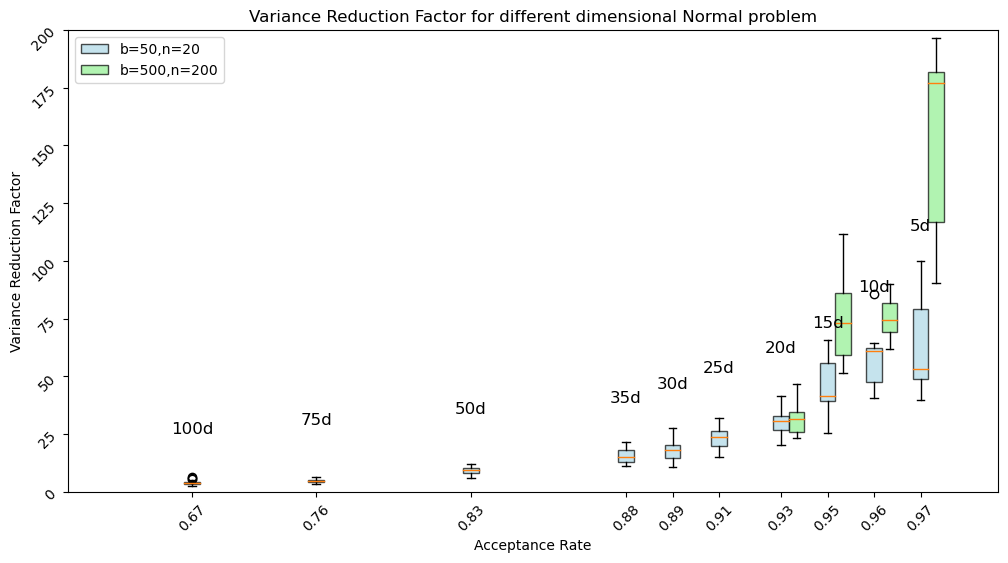

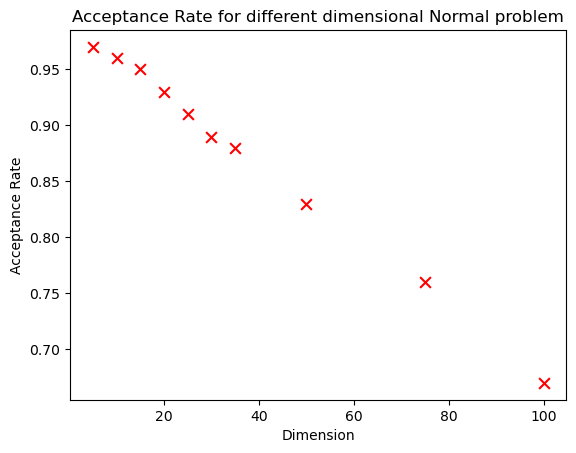

In [27]:
strs = ['5', '10', '15','20','25','30','35','50','75','100']
IMCVS = []
IMCVS2 = []
accs = []
for i in strs:
    f = open('N'+i+'.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    accs.append(a[0:4])
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVS.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVS2.append(c)

strs2 = ['5', '10', '15','20']
IMCVS3 = []
IMCVS4 = []
accs2 = []
for i in strs2:
    f = open('resultN'+i+'_2.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    accs2.append(a[0:4])
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVS3.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVS4.append(c)

fig, axs = plt.subplots(figsize=(12, 6))
axs.set_xlim(0.7, 1)
axs.set_ylim(0, 200)
axs.tick_params(rotation=45)
axs.set_title('Variance Reduction Factor for different dimensional Normal problem')
axs.set_ylabel('Variance Reduction Factor')
axs.set_xlabel('Acceptance Rate')
pos = [0.975,0.96,0.945,0.93,0.91,0.895,0.88,0.83,0.78, 0.74]
pos2 = [0.98,0.965,0.95,0.935]
for i in range(len(strs)):
    axs.text(pos[i], 115 - np.log(i+1) / np.log(1.3) * 10, strs[i] + 'd', fontsize=12, horizontalalignment='center', verticalalignment='center',  c='black')
bp1 = axs.boxplot(IMCVS2, widths=0.005, positions= pos,patch_artist=True)
bp2 = axs.boxplot(IMCVS4, widths=0.005, positions= pos2,patch_artist=True)
axs.set_xticks(pos, accs)
[bp1['boxes'][i].set(facecolor='lightblue', alpha=0.7) for i in range(len(strs))]
[bp2['boxes'][i].set(facecolor='lightgreen', alpha=0.7) for i in range(len(strs2))]

axs.legend([bp1["boxes"][0], bp2["boxes"][0]], ['b=50,n=20', 'b=500,n=200'], loc='upper left')
plt.show()
plt.scatter([5,10,15,20,25,30,35,50,75,100],[0.97,0.96,0.95,0.93,0.91,0.89,0.88,0.83,0.76,0.67], marker='x',s=60, c = 'r')
plt.title('Acceptance Rate for different dimensional Normal problem')
plt.ylabel('Acceptance Rate')
plt.xlabel('Dimension')
plt.show()

['0.93', '0.81']


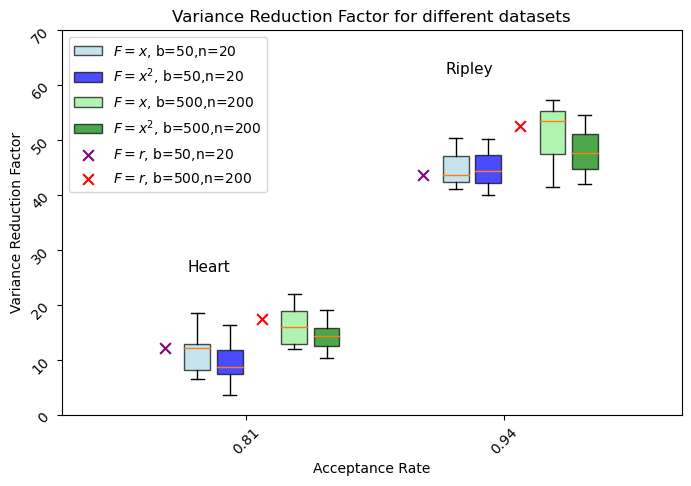

In [61]:
strs = ['ripley', 'heart']
IMCVS = []
IMCVS2 = []
accs = []
for i in strs:
    f = open('result'+i+'.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    accs.append(a[0:4])
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVS.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVS2.append(c)
print(str(accs))

IMCVL = []
IMCVL2 = []
strsL = ['ripley', 'heart']
for i in strsL:
    f = open(i+'L.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVL.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVL2.append(c)


fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Variance Reduction Factor for different datasets')
ax.set_ylabel('Variance Reduction Factor')
ax.set_xlabel('Acceptance Rate')
ax.set_ylim(0, 70)
ax.tick_params(labelrotation=45)
ax.set_xlim(0.62, 1.1)
base1 = 0.9
base2 = 0.7
interval = 0.025
pos1 = [base1, base2]
pos2 = [base1 + interval, base2 + interval]
pos3 = [base1 + 2 * interval, base2 + 2 * interval]
pos4 = [base1 + 3 * interval, base2 + 3 * interval]
pos5 = [base1 + 4 * interval, base2 + 4 * interval]
pos6 = [base1 + 5 * interval, base2 + 5 * interval]
posm = [base1 + 2.5 * interval, base2 + 2.5 * interval]

bp1 = ax.boxplot(IMCVS,widths= interval - 0.005, positions = pos2, patch_artist=True)
bp2 = ax.boxplot(IMCVS2,widths= interval - 0.005, positions =  pos3, patch_artist=True)
bp3 = ax.boxplot(IMCVL,widths=interval - 0.005, positions = pos5, patch_artist=True)
bp4 = ax.boxplot(IMCVL2,widths=interval - 0.005, positions =  pos6, patch_artist=True)

p1 = ax.scatter(pos1,[43.6,12.2], marker='x',s=60, c = 'purple')
p2 = ax.scatter(pos4,[52.5,17.4], marker='x',s=60, c = 'red')

ax.set_xticks(posm,[0.94,0.81])
[bp1['boxes'][i].set(facecolor='lightblue', alpha=0.7) for i in range(2)]
[bp2['boxes'][i].set(facecolor='blue', alpha=0.7) for i in range(2)]
[bp3['boxes'][i].set(facecolor='lightgreen', alpha=0.7) for i in range(2)]
[bp4['boxes'][i].set(facecolor='green', alpha=0.7) for i in range(2)]
ax.text(base1 + 0.7*interval, 62, 'Ripley', fontsize=11)
ax.text(base2 + 0.7*interval, 26, 'Heart', fontsize=11)

ax.legend([bp1["boxes"][0], bp2["boxes"][0], bp3["boxes"][0], bp4["boxes"][0], p1, p2], 
          ['$F=x$, b=50,n=20', '$F=x^2$, b=50,n=20', '$F=x$, b=500,n=200', '$F=x^2$, b=500,n=200', '$F=r$, b=50,n=20', '$F=r$, b=500,n=200'], loc='upper left')
plt.show()